# A Simple Forecast and Stock Calculation

For one product in one store, I use the last 28 sales days to estimate daily sales for the next week. The example then calculates a reorder point and a weekly order-up-to level.

## 1. Assumptions

Supplier lead time is fixed at 7 days. The buffer uses a normal approximation with a one-sided 95% cycle-service target (`z = 1.65`). It assumes independent daily demand with a stable mean and variance. These assumptions are illustrative; the calculation does not establish a 95% fill rate.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

sales_path = "data/raw/sales_train_validation.csv"
calendar_path = "data/raw/calendar.csv"
sales = pd.read_csv(sales_path)
calendar = pd.read_csv(calendar_path)
day_columns = [column for column in sales.columns if column.startswith("d_")]
lead_time_days = 7
review_window_days = 28
service_level_multiplier = 1.65
print(f"Products and stores: {sales.shape[0]:,} combinations")
print(f"Observed days: {len(day_columns):,}")

Products and stores: 30,490 combinations
Observed days: 1,913


## 2. Select an example

Use the product-store row with the highest total historical sales to show the calculation. This is a high-volume example, so it does not demonstrate performance on typical or intermittent-selling items.

In [2]:
sales["total_units"] = sales[day_columns].sum(axis=1)
example = sales.loc[sales["total_units"].idxmax()]
example_id = example["id"]
example_sales = example[day_columns].astype(float).reset_index()
example_sales.columns = ["d", "units_sold"]
example_sales = example_sales.merge(calendar[["d", "date"]], on="d", how="left")
example_sales["date"] = pd.to_datetime(example_sales["date"])
print(f"Example: {example_id}")
print(f"Item: {example['item_id']} | Store: {example['store_id']}")
example_sales.tail()

Example: FOODS_3_090_CA_3_validation
Item: FOODS_3_090 | Store: CA_3


,d,units_sold,date
1908,d_1909,88.0,2016-04-20
1909,d_1910,77.0,2016-04-21
1910,d_1911,141.0,2016-04-22
1911,d_1912,139.0,2016-04-23
1912,d_1913,130.0,2016-04-24


## 3. Next-week baseline

Use the mean of the latest 28 observed days for each forecast day. This ignores weekday effects and trends. Forecast accuracy has not been tested on held-out dates.

In [3]:
recent = example_sales.tail(review_window_days).copy()
average_daily_demand = recent["units_sold"].mean()
demand_std = recent["units_sold"].std(ddof=1)
forecast = pd.DataFrame({"horizon_day": range(1, lead_time_days + 1)})
forecast["forecast_units"] = average_daily_demand
forecast

,horizon_day,forecast_units
0,1,110.357143
1,2,110.357143
2,3,110.357143
3,4,110.357143
4,5,110.357143
5,6,110.357143
6,7,110.357143


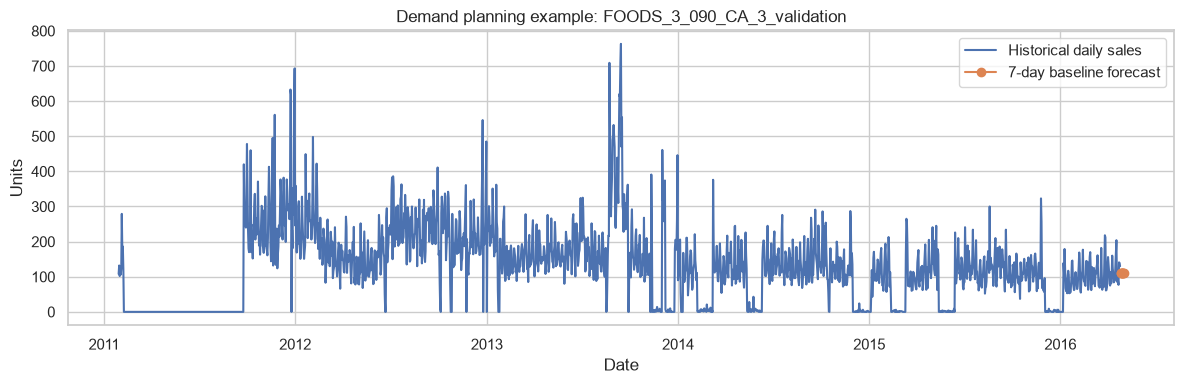

In [4]:
plt.figure(figsize=(12, 4))
plt.plot(example_sales["date"], example_sales["units_sold"], label="Historical daily sales")
forecast_dates = pd.date_range(example_sales["date"].max() + pd.Timedelta(days=1), periods=lead_time_days)
plt.plot(forecast_dates, forecast["forecast_units"], marker="o", label="7-day baseline forecast")
plt.title(f"Demand planning example: {example_id}")
plt.xlabel("Date")
plt.ylabel("Units")
plt.legend()
plt.tight_layout()
plt.show()

## 4. Reorder point

Under continuous review, place an order when the inventory position reaches the reorder point. Inventory position means on-hand stock plus incoming orders minus backorders.

`Reorder point = mean daily demand × lead time + safety stock`

`Safety stock = z × daily standard deviation × √lead time`

Here, recorded sales stand in for demand. Stockouts could bias both the mean and variability.

In [5]:
safety_stock = service_level_multiplier * demand_std * np.sqrt(lead_time_days)
reorder_point = average_daily_demand * lead_time_days + safety_stock
planning_summary = pd.DataFrame({
    "metric": ["Average daily demand", "Demand standard deviation", "Safety stock", "Reorder point"],
    "units": [average_daily_demand, demand_std, safety_stock, reorder_point]
})
planning_summary.round(1)

,metric,units
0,Average daily demand,110.4
1,Demand standard deviation,34.8
2,Safety stock,151.9
3,Reorder point,924.4


## 5. Weekly review example

For review every 7 days, the order-up-to level covers both the lead time and the interval until the next review. Its buffer must also cover that full period. This is a periodic-review calculation, separate from the continuous-review reorder point above.

The inventory position below is an example input of zero, not a value observed in the dataset. Round the order up to whole units; pack sizes and supplier limits are not included.

In [6]:
review_period_days = 7
protection_period_days = lead_time_days + review_period_days
review_safety_stock = service_level_multiplier * demand_std * np.sqrt(protection_period_days)
target_stock = average_daily_demand * protection_period_days + review_safety_stock
current_inventory_position = 0
suggested_order_quantity = int(np.ceil(max(0, target_stock - current_inventory_position)))
order_summary = pd.DataFrame({
    "metric": ["Target stock level", "Current inventory position", "Suggested order quantity"],
    "units": [target_stock, current_inventory_position, suggested_order_quantity]
})
order_summary.round(1)

,metric,units
0,Target stock level,1759.8
1,Current inventory position,0.0
2,Suggested order quantity,1760.0


## 6. Limits and next steps

The forecast and order quantity illustrate the arithmetic for one item. Before using them for purchases, test forecasts on held-out dates, check weekday effects and obtain actual stock positions, delivery times, pack sizes and shelf-life limits. Historical sales variability may not describe future demand or forecast errors.